In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

BASE_DIR = Path(r"C:\Users\Luciano Sotelo\Documents\TESIS_PODER_JUDICIAL")

RUTA_LIMPIA = BASE_DIR / "02_datos_limpios" / "base_poder_judicial_limpia_v1.xlsx"
CARPETA_GRAFICOS = BASE_DIR / "04_graficos_resultados"
CARPETA_GRAFICOS.mkdir(exist_ok=True)

RUTA_RESUMEN = BASE_DIR / "02_datos_limpios" / "resumen_resultados_v1.xlsx"

df = pd.read_excel(RUTA_LIMPIA)

print("Filas:", df.shape[0])
print("Columnas:", df.shape[1])

df.head()

Filas: 9695
Columnas: 64


,Fecha Intervención,Sexo denunciante,Edad denunciante,Relación denunciante/denunciada,Capacidades Diferentes denunciante,Pertenencia a Pueblos Originarios denunciante,Violencia Física,Violencia Psicológica,Violencia Económica,Violencia Sexual,...,Año,Mes,Edad denunciante limpia,Edad denunciada limpia,Violencia Física constatada,Violencia Psicológica constatada,Violencia Económica constatada,Violencia Sexual constatada,Violencia Restricción Participación Social constatada,Violencia Ambiental constatada
0,2022-03-21,F,26,7.0,2.0,2.0,0,3,0,0,...,2022,3,26.0,34.0,0,1,0,0,0,1
1,2022-04-01,F,11,5.0,1.0,2.0,0,0,0,1,...,2022,4,11.0,31.0,0,0,0,1,0,0
2,2022-04-29,F,23,2.0,2.0,2.0,3,2,0,0,...,2022,4,23.0,32.0,1,1,0,0,0,1
3,2022-04-07,F,21,1.0,1.0,2.0,2,3,3,0,...,2022,4,21.0,24.0,1,1,1,0,1,1
4,2022-01-04,F,27,1.0,2.0,2.0,2,3,2,0,...,2022,1,27.0,33.0,1,1,1,0,1,1


In [4]:
def guardar_grafico(nombre_archivo):
    ruta = CARPETA_GRAFICOS / nombre_archivo
    plt.tight_layout()
    plt.savefig(ruta, dpi=300, bbox_inches="tight")
    plt.show()
    print("Gráfico guardado en:", ruta)

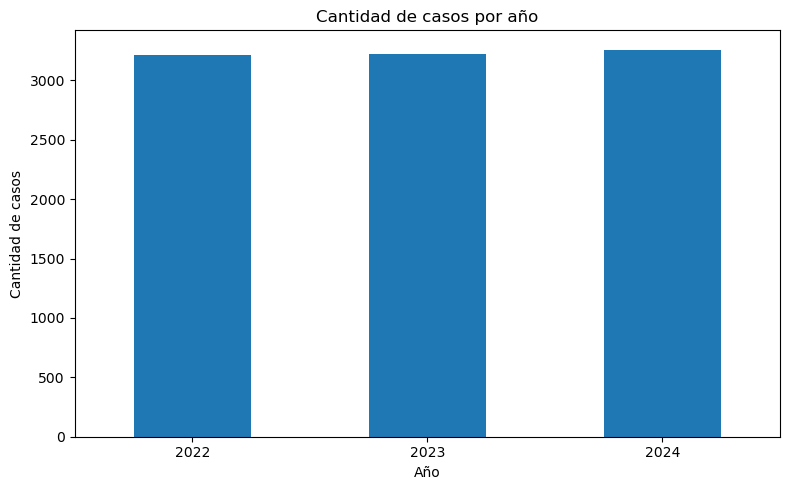

Gráfico guardado en: C:\Users\Luciano Sotelo\Documents\TESIS_PODER_JUDICIAL\04_graficos_resultados\01_casos_por_anio.png


Año
2022    3213
2023    3223
2024    3259
Name: count, dtype: int64

In [5]:
casos_por_anio = df["Año"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
casos_por_anio.plot(kind="bar")
plt.title("Cantidad de casos por año")
plt.xlabel("Año")
plt.ylabel("Cantidad de casos")
plt.xticks(rotation=0)

guardar_grafico("01_casos_por_anio.png")

casos_por_anio

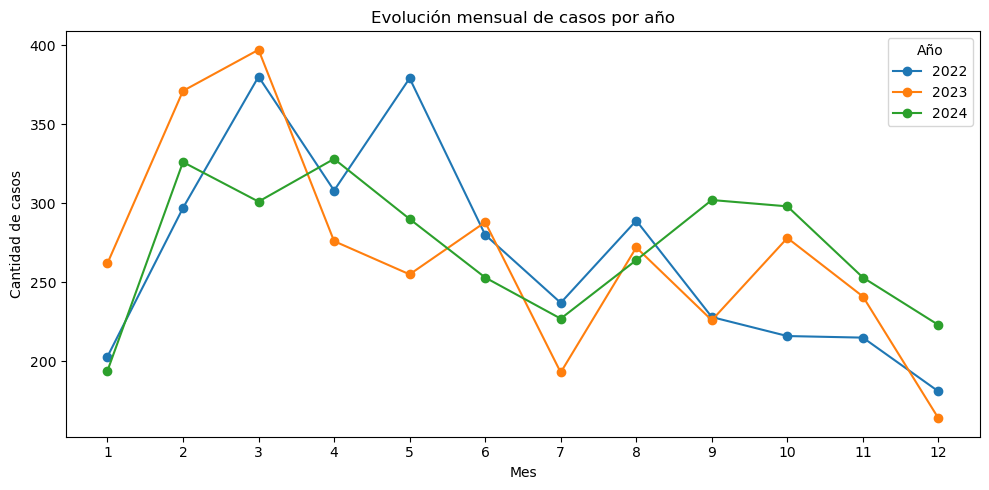

Gráfico guardado en: C:\Users\Luciano Sotelo\Documents\TESIS_PODER_JUDICIAL\04_graficos_resultados\02_evolucion_mensual_casos.png


,Año,Mes,Cantidad de casos
0,2022,1,203
1,2022,2,297
2,2022,3,380
3,2022,4,308
4,2022,5,379


In [6]:
casos_mes_anio = (
    df.groupby(["Año", "Mes"])
    .size()
    .reset_index(name="Cantidad de casos")
)

plt.figure(figsize=(10, 5))

for anio in sorted(casos_mes_anio["Año"].dropna().unique()):
    datos_anio = casos_mes_anio[casos_mes_anio["Año"] == anio]
    plt.plot(datos_anio["Mes"], datos_anio["Cantidad de casos"], marker="o", label=int(anio))

plt.title("Evolución mensual de casos por año")
plt.xlabel("Mes")
plt.ylabel("Cantidad de casos")
plt.xticks(range(1, 13))
plt.legend(title="Año")

guardar_grafico("02_evolucion_mensual_casos.png")

casos_mes_anio.head()

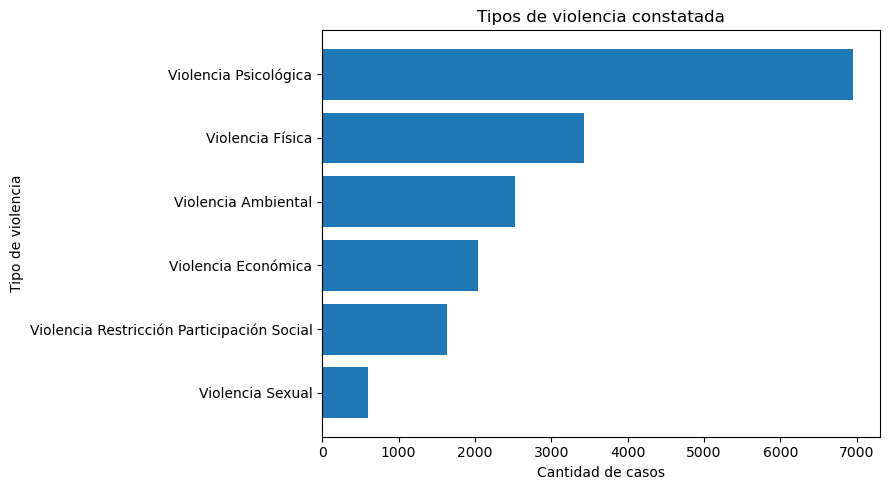

Gráfico guardado en: C:\Users\Luciano Sotelo\Documents\TESIS_PODER_JUDICIAL\04_graficos_resultados\03_tipos_violencia_constatada.png


,Tipo de violencia,Casos,Porcentaje
1,Violencia Psicológica,6957,71.76
0,Violencia Física,3428,35.36
5,Violencia Ambiental,2520,25.99
2,Violencia Económica,2038,21.02
4,Violencia Restricción Participación Social,1633,16.84
3,Violencia Sexual,599,6.18


In [7]:
variables_violencia = [
    "Violencia Física",
    "Violencia Psicológica",
    "Violencia Económica",
    "Violencia Sexual",
    "Violencia Restricción Participación Social",
    "Violencia Ambiental"
]

resumen_violencias = []

for col in variables_violencia:
    casos = (df[col] > 0).sum()
    porcentaje = casos / len(df) * 100
    
    resumen_violencias.append({
        "Tipo de violencia": col,
        "Casos": casos,
        "Porcentaje": round(porcentaje, 2)
    })

resumen_violencias = pd.DataFrame(resumen_violencias)
resumen_violencias = resumen_violencias.sort_values("Casos", ascending=True)

plt.figure(figsize=(9, 5))
plt.barh(resumen_violencias["Tipo de violencia"], resumen_violencias["Casos"])
plt.title("Tipos de violencia constatada")
plt.xlabel("Cantidad de casos")
plt.ylabel("Tipo de violencia")

guardar_grafico("03_tipos_violencia_constatada.png")

resumen_violencias.sort_values("Casos", ascending=False)

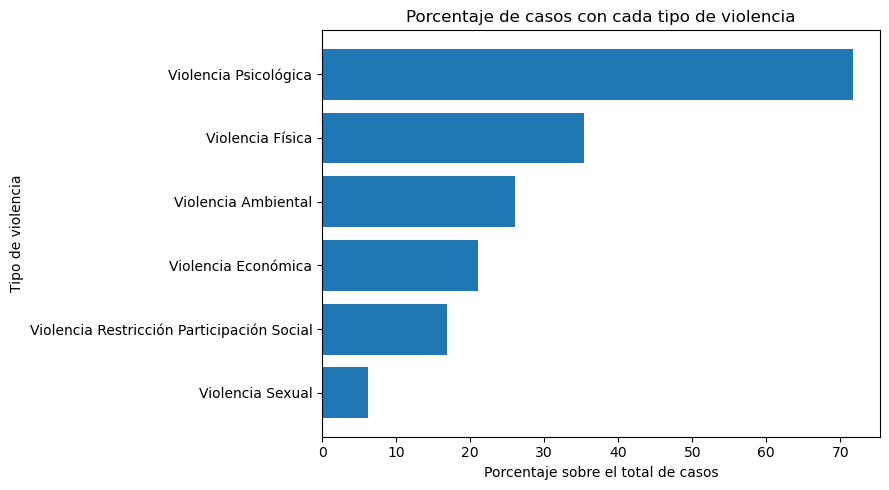

Gráfico guardado en: C:\Users\Luciano Sotelo\Documents\TESIS_PODER_JUDICIAL\04_graficos_resultados\04_porcentaje_tipos_violencia.png


,Tipo de violencia,Casos,Porcentaje
1,Violencia Psicológica,6957,71.76
0,Violencia Física,3428,35.36
5,Violencia Ambiental,2520,25.99
2,Violencia Económica,2038,21.02
4,Violencia Restricción Participación Social,1633,16.84
3,Violencia Sexual,599,6.18


In [8]:
resumen_violencias_pct = resumen_violencias.sort_values("Porcentaje", ascending=True)

plt.figure(figsize=(9, 5))
plt.barh(resumen_violencias_pct["Tipo de violencia"], resumen_violencias_pct["Porcentaje"])
plt.title("Porcentaje de casos con cada tipo de violencia")
plt.xlabel("Porcentaje sobre el total de casos")
plt.ylabel("Tipo de violencia")

guardar_grafico("04_porcentaje_tipos_violencia.png")

resumen_violencias_pct.sort_values("Porcentaje", ascending=False)

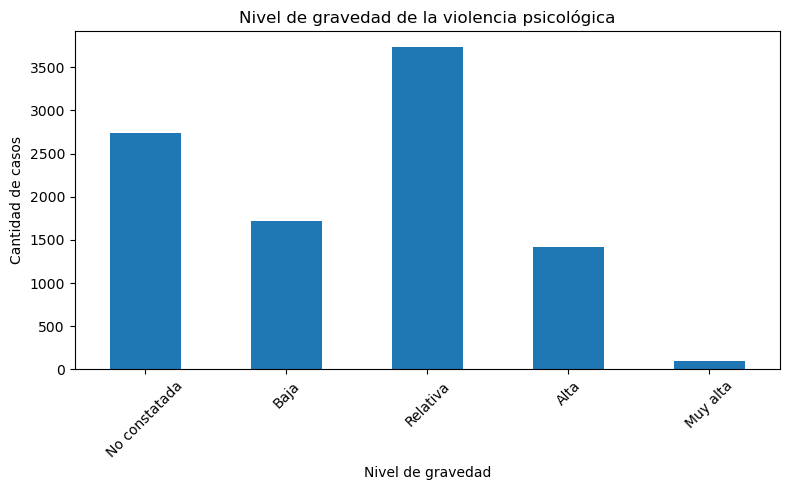

Gráfico guardado en: C:\Users\Luciano Sotelo\Documents\TESIS_PODER_JUDICIAL\04_graficos_resultados\05_gravedad_violencia_psicologica.png


Violencia Psicológica
No constatada    2738
Baja             1721
Relativa         3729
Alta             1414
Muy alta           93
Name: count, dtype: int64

In [9]:
mapa_gravedad = {
    0: "No constatada",
    1: "Baja",
    2: "Relativa",
    3: "Alta",
    4: "Muy alta"
}

gravedad_psicologica = (
    df["Violencia Psicológica"]
    .map(mapa_gravedad)
    .value_counts()
    .reindex(["No constatada", "Baja", "Relativa", "Alta", "Muy alta"])
)

plt.figure(figsize=(8, 5))
gravedad_psicologica.plot(kind="bar")
plt.title("Nivel de gravedad de la violencia psicológica")
plt.xlabel("Nivel de gravedad")
plt.ylabel("Cantidad de casos")
plt.xticks(rotation=45)

guardar_grafico("05_gravedad_violencia_psicologica.png")

gravedad_psicologica

In [10]:
tabla_gravedad_violencias = pd.DataFrame()

for col in variables_violencia:
    conteo = (
        df[col]
        .map(mapa_gravedad)
        .value_counts()
        .reindex(["No constatada", "Baja", "Relativa", "Alta", "Muy alta"])
    )
    tabla_gravedad_violencias[col] = conteo

tabla_gravedad_violencias

,Violencia Física,Violencia Psicológica,Violencia Económica,Violencia Sexual,Violencia Restricción Participación Social,Violencia Ambiental
Violencia Física,,,,,,
No constatada,6267,2738,7657,9096,8062,7175
Baja,1021,1721,450,127,294,479
Relativa,1674,3729,1154,286,924,1396
Alta,686,1414,414,158,378,592
Muy alta,47,93,20,28,37,53


<Figure size 1000x600 with 0 Axes>

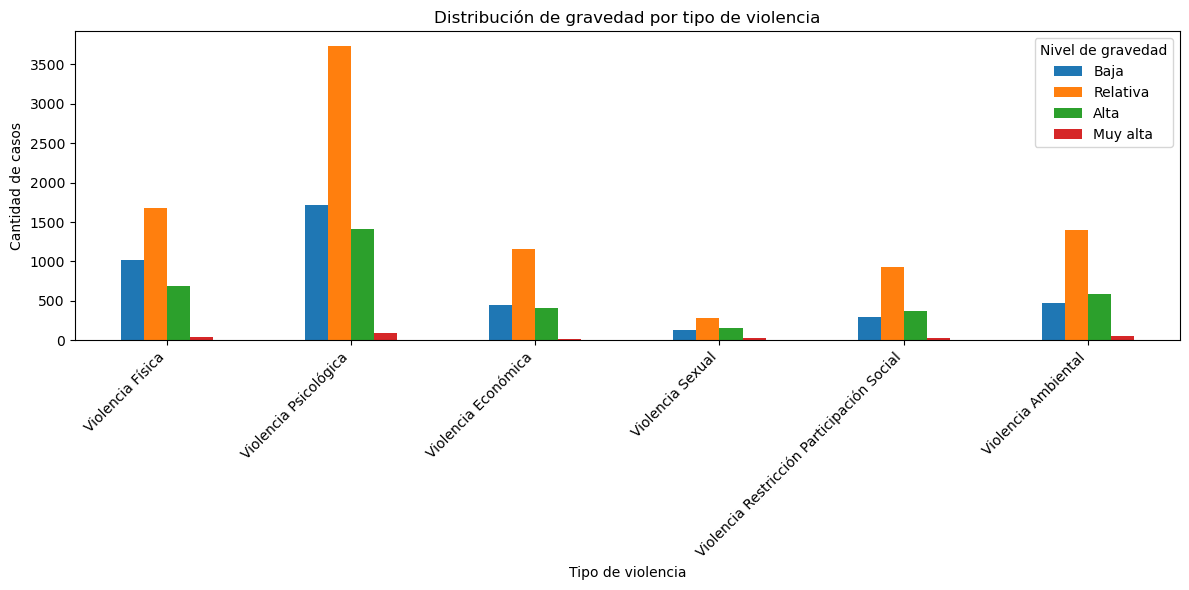

Gráfico guardado en: C:\Users\Luciano Sotelo\Documents\TESIS_PODER_JUDICIAL\04_graficos_resultados\06_gravedad_por_tipo_violencia.png


In [11]:
tabla_gravedad_sin_no = tabla_gravedad_violencias.drop(index="No constatada")

plt.figure(figsize=(10, 6))
tabla_gravedad_sin_no.T.plot(kind="bar", figsize=(12, 6))
plt.title("Distribución de gravedad por tipo de violencia")
plt.xlabel("Tipo de violencia")
plt.ylabel("Cantidad de casos")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Nivel de gravedad")

guardar_grafico("06_gravedad_por_tipo_violencia.png")

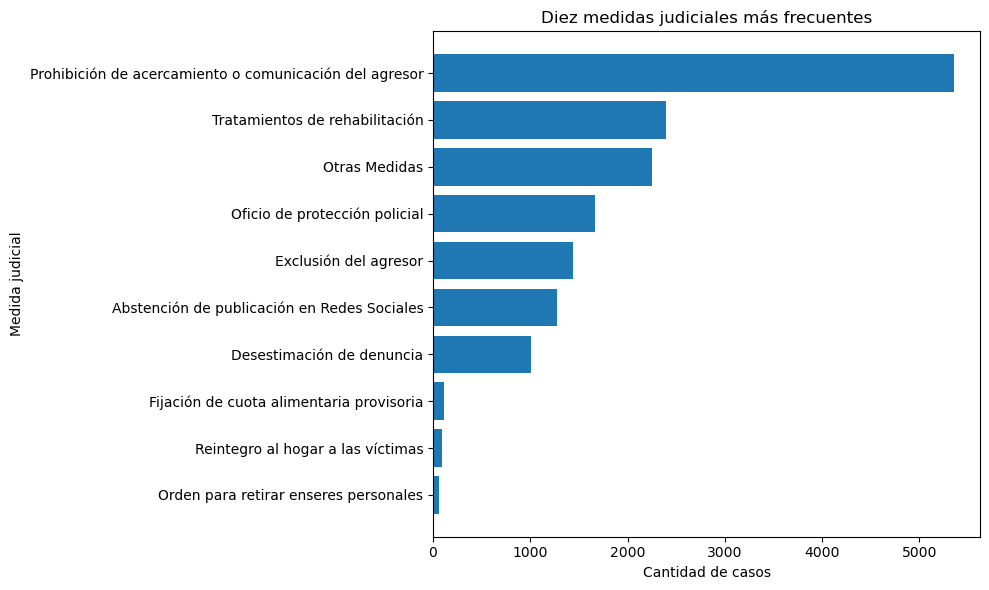

Gráfico guardado en: C:\Users\Luciano Sotelo\Documents\TESIS_PODER_JUDICIAL\04_graficos_resultados\07_top_10_medidas_judiciales.png


,Medida judicial,Casos,Porcentaje
13,Prohibición de acercamiento o comunicación del...,5355,55.23
20,Tratamientos de rehabilitación,2392,24.67
12,Otras Medidas,2255,23.26
10,Oficio de protección policial,1660,17.12
4,Exclusión del agresor,1436,14.81
0,Abstención de publicación en Redes Sociales,1272,13.12
3,Desestimación de denuncia,1005,10.37
5,Fijación de cuota alimentaria provisoria,117,1.21
15,Reintegro al hogar a las víctimas,95,0.98
11,Orden para retirar enseres personales,62,0.64


In [12]:
medidas_judiciales = [
    "Abstención de publicación en Redes Sociales",
    "Alojamiento temporario de la víctima",
    "Custodia policial",
    "Desestimación de denuncia",
    "Exclusión del agresor",
    "Fijación de cuota alimentaria provisoria",
    "Fijación de régimen de visitas",
    "Guarda de menores/incapaces",
    "Guarda de menores/incapaces víctimas",
    "Levantamiento de la medida judicial",
    "Oficio de protección policial",
    "Orden para retirar enseres personales",
    "Otras Medidas",
    "Prohibición de acercamiento o comunicación del agresor",
    "Recursos de Revocatoria",
    "Reintegro al hogar a las víctimas",
    "Restitución de alimentos",
    "Restitución de bienes",
    "Retiro de la víctima",
    "Secuestro de arma",
    "Tratamientos de rehabilitación"
]

resumen_medidas = []

for col in medidas_judiciales:
    if col in df.columns:
        casos = pd.to_numeric(df[col], errors="coerce").fillna(0).sum()
        porcentaje = casos / len(df) * 100
        
        resumen_medidas.append({
            "Medida judicial": col,
            "Casos": int(casos),
            "Porcentaje": round(porcentaje, 2)
        })

resumen_medidas = pd.DataFrame(resumen_medidas)
resumen_medidas = resumen_medidas.sort_values("Casos", ascending=False)

top_medidas = resumen_medidas.head(10).sort_values("Casos", ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(top_medidas["Medida judicial"], top_medidas["Casos"])
plt.title("Diez medidas judiciales más frecuentes")
plt.xlabel("Cantidad de casos")
plt.ylabel("Medida judicial")

guardar_grafico("07_top_10_medidas_judiciales.png")

resumen_medidas.head(10)

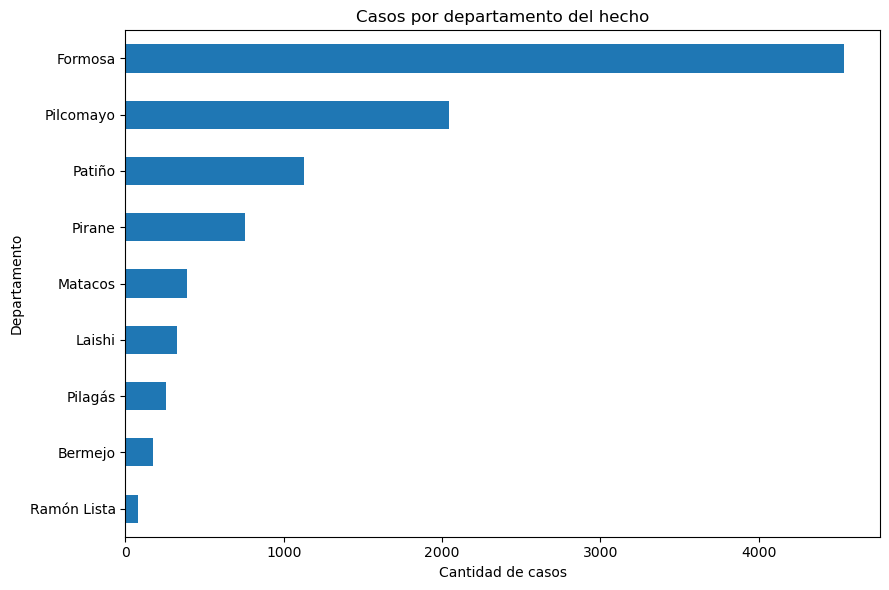

Gráfico guardado en: C:\Users\Luciano Sotelo\Documents\TESIS_PODER_JUDICIAL\04_graficos_resultados\08_casos_por_departamento.png


Departamento Hecho
Formosa        4539
Pilcomayo      2046
Patiño         1126
Pirane          753
Matacos         391
Laishi          327
Pilagás         257
Bermejo         174
Ramón Lista      81
Name: count, dtype: int64

In [13]:
casos_departamento = (
    df["Departamento Hecho"]
    .value_counts()
    .head(15)
    .sort_values(ascending=True)
)

plt.figure(figsize=(9, 6))
casos_departamento.plot(kind="barh")
plt.title("Casos por departamento del hecho")
plt.xlabel("Cantidad de casos")
plt.ylabel("Departamento")

guardar_grafico("08_casos_por_departamento.png")

casos_departamento.sort_values(ascending=False)

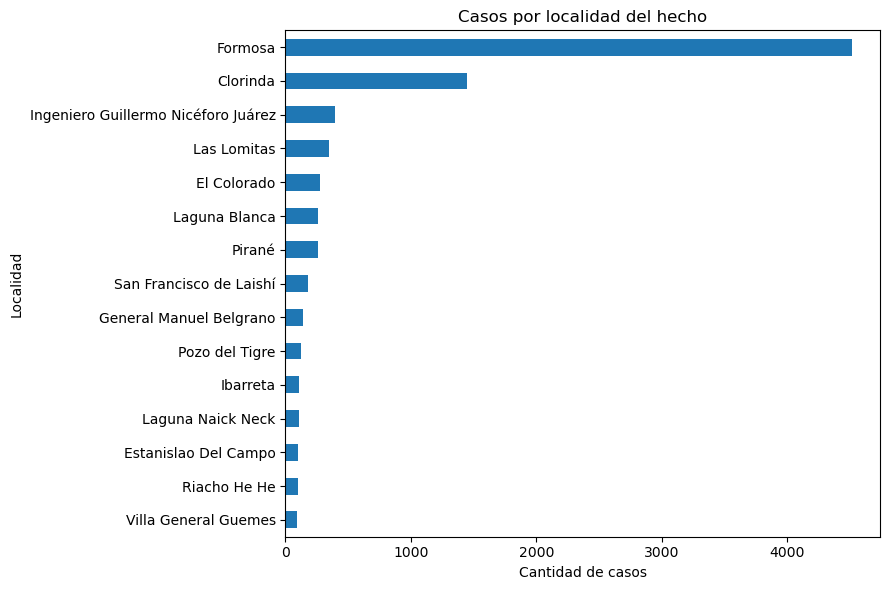

Gráfico guardado en: C:\Users\Luciano Sotelo\Documents\TESIS_PODER_JUDICIAL\04_graficos_resultados\09_casos_por_localidad.png


Localidad Hecho
Formosa                                4513
Clorinda                               1444
Ingeniero Guillermo Nicéforo Juárez     392
Las Lomitas                             350
El Colorado                             279
Laguna Blanca                           263
Pirané                                  257
San Francisco de Laishí                 182
General Manuel Belgrano                 143
Pozo del Tigre                          121
Ibarreta                                112
Laguna Naick Neck                       111
Estanislao Del Campo                    103
Riacho He He                            100
Villa General Guemes                     93
Name: count, dtype: int64

In [14]:
casos_localidad = (
    df["Localidad Hecho"]
    .value_counts()
    .head(15)
    .sort_values(ascending=True)
)

plt.figure(figsize=(9, 6))
casos_localidad.plot(kind="barh")
plt.title("Casos por localidad del hecho")
plt.xlabel("Cantidad de casos")
plt.ylabel("Localidad")

guardar_grafico("09_casos_por_localidad.png")

casos_localidad.sort_values(ascending=False)

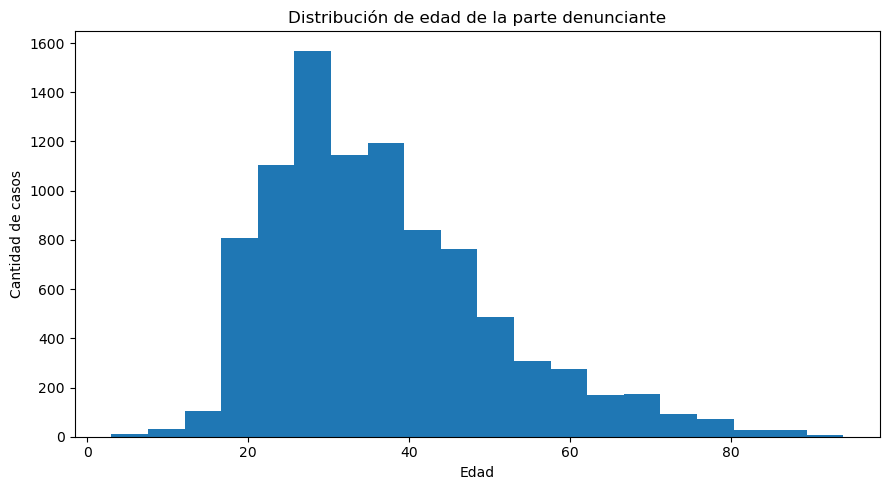

Gráfico guardado en: C:\Users\Luciano Sotelo\Documents\TESIS_PODER_JUDICIAL\04_graficos_resultados\10_distribucion_edad_denunciante.png


count    9205.000000
mean       36.641173
std        14.001318
min         3.000000
25%        26.000000
50%        34.000000
75%        44.000000
max        94.000000
Name: Edad denunciante limpia, dtype: float64

In [15]:
plt.figure(figsize=(9, 5))
df["Edad denunciante limpia"].dropna().plot(kind="hist", bins=20)
plt.title("Distribución de edad de la parte denunciante")
plt.xlabel("Edad")
plt.ylabel("Cantidad de casos")

guardar_grafico("10_distribucion_edad_denunciante.png")

df["Edad denunciante limpia"].describe()

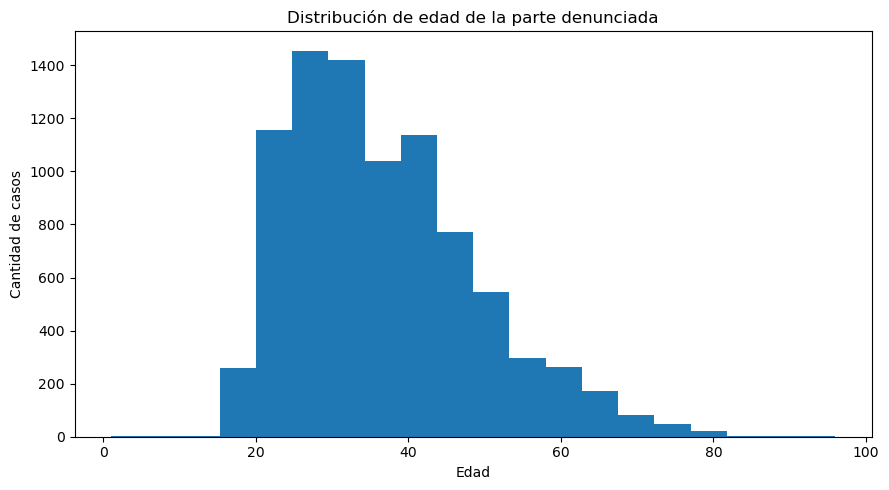

Gráfico guardado en: C:\Users\Luciano Sotelo\Documents\TESIS_PODER_JUDICIAL\04_graficos_resultados\11_distribucion_edad_denunciada.png


count    8686.000000
mean       36.621690
std        12.327319
min         1.000000
25%        27.000000
50%        35.000000
75%        44.000000
max        96.000000
Name: Edad denunciada limpia, dtype: float64

In [16]:
plt.figure(figsize=(9, 5))
df["Edad denunciada limpia"].dropna().plot(kind="hist", bins=20)
plt.title("Distribución de edad de la parte denunciada")
plt.xlabel("Edad")
plt.ylabel("Cantidad de casos")

guardar_grafico("11_distribucion_edad_denunciada.png")

df["Edad denunciada limpia"].describe()

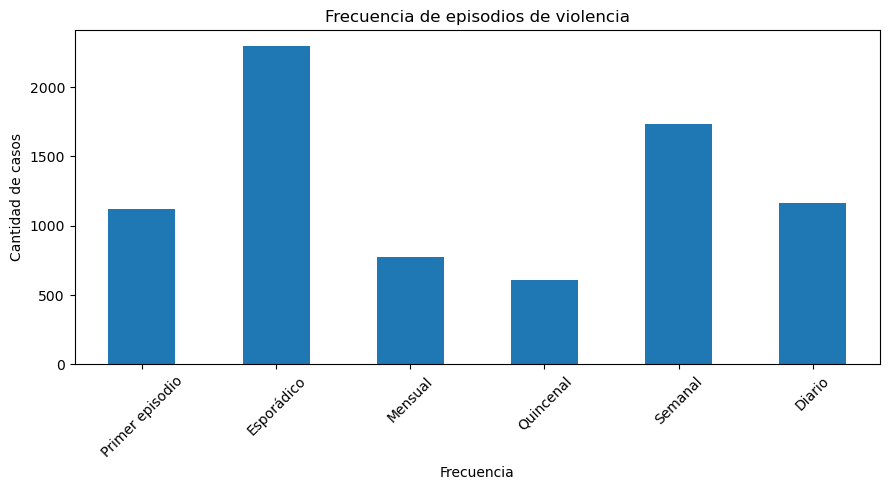

Gráfico guardado en: C:\Users\Luciano Sotelo\Documents\TESIS_PODER_JUDICIAL\04_graficos_resultados\12_frecuencia_episodios.png


Frecuencia de Episodios
Primer episodio    1122
Esporádico         2295
Mensual             772
Quincenal           607
Semanal            1732
Diario             1166
Name: count, dtype: int64

In [17]:
mapa_frecuencia = {
    1: "Primer episodio",
    2: "Esporádico",
    3: "Mensual",
    4: "Quincenal",
    5: "Semanal",
    6: "Diario"
}

frecuencia_episodios = (
    df["Frecuencia de Episodios"]
    .map(mapa_frecuencia)
    .value_counts()
    .reindex(["Primer episodio", "Esporádico", "Mensual", "Quincenal", "Semanal", "Diario"])
)

plt.figure(figsize=(9, 5))
frecuencia_episodios.plot(kind="bar")
plt.title("Frecuencia de episodios de violencia")
plt.xlabel("Frecuencia")
plt.ylabel("Cantidad de casos")
plt.xticks(rotation=45)

guardar_grafico("12_frecuencia_episodios.png")

frecuencia_episodios

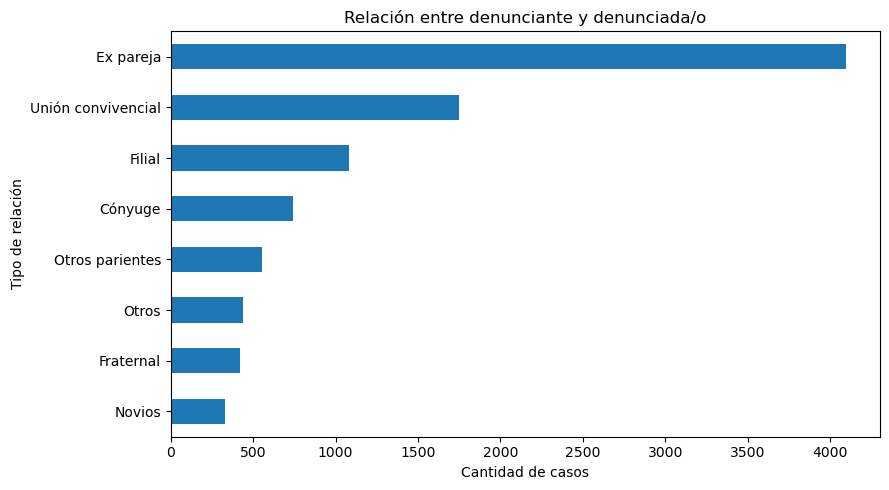

Gráfico guardado en: C:\Users\Luciano Sotelo\Documents\TESIS_PODER_JUDICIAL\04_graficos_resultados\13_relacion_denunciante_denunciada.png


Relación denunciante/denunciada
Ex pareja             4098
Unión convivencial    1750
Filial                1082
Cónyuge                740
Otros parientes        553
Otros                  439
Fraternal              420
Novios                 330
Name: count, dtype: int64

In [18]:
mapa_relacion = {
    1: "Unión convivencial",
    2: "Cónyuge",
    3: "Filial",
    4: "Fraternal",
    5: "Otros",
    6: "Novios",
    7: "Ex pareja",
    8: "Otros parientes"
}

relacion = (
    df["Relación denunciante/denunciada"]
    .map(mapa_relacion)
    .value_counts()
    .sort_values(ascending=True)
)

plt.figure(figsize=(9, 5))
relacion.plot(kind="barh")
plt.title("Relación entre denunciante y denunciada/o")
plt.xlabel("Cantidad de casos")
plt.ylabel("Tipo de relación")

guardar_grafico("13_relacion_denunciante_denunciada.png")

relacion.sort_values(ascending=False)

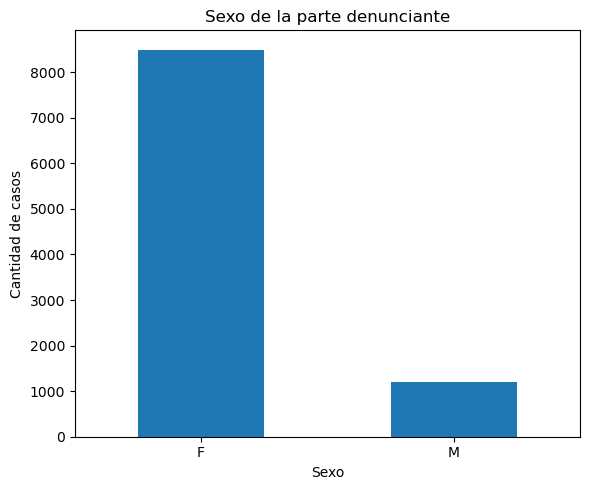

Gráfico guardado en: C:\Users\Luciano Sotelo\Documents\TESIS_PODER_JUDICIAL\04_graficos_resultados\14_sexo_denunciante.png


Sexo denunciante
F    8494
M    1201
Name: count, dtype: int64

In [19]:
sexo_denunciante = df["Sexo denunciante"].value_counts()

plt.figure(figsize=(6, 5))
sexo_denunciante.plot(kind="bar")
plt.title("Sexo de la parte denunciante")
plt.xlabel("Sexo")
plt.ylabel("Cantidad de casos")
plt.xticks(rotation=0)

guardar_grafico("14_sexo_denunciante.png")

sexo_denunciante

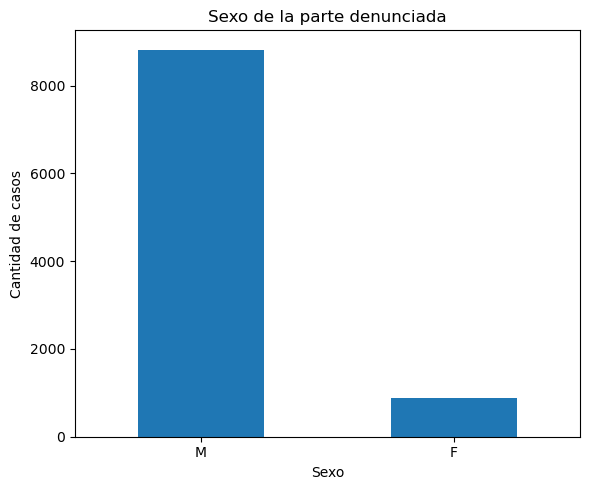

Gráfico guardado en: C:\Users\Luciano Sotelo\Documents\TESIS_PODER_JUDICIAL\04_graficos_resultados\15_sexo_denunciada.png


Sexo denunciada
M    8817
F     878
Name: count, dtype: int64

In [20]:
sexo_denunciada = df["Sexo denunciada"].value_counts()

plt.figure(figsize=(6, 5))
sexo_denunciada.plot(kind="bar")
plt.title("Sexo de la parte denunciada")
plt.xlabel("Sexo")
plt.ylabel("Cantidad de casos")
plt.xticks(rotation=0)

guardar_grafico("15_sexo_denunciada.png")

sexo_denunciada

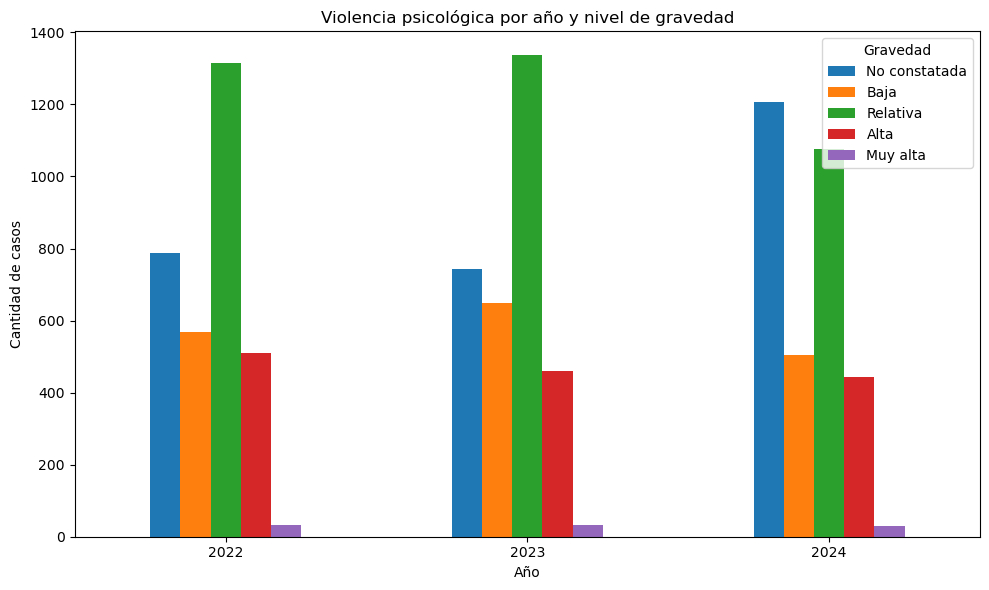

Gráfico guardado en: C:\Users\Luciano Sotelo\Documents\TESIS_PODER_JUDICIAL\04_graficos_resultados\16_violencia_psicologica_por_anio.png


Violencia Psicológica,No constatada,Baja,Relativa,Alta,Muy alta
Año,,,,,
2022,788,567,1316,510,32
2023,744,650,1336,461,32
2024,1206,504,1077,443,29


In [21]:
violencia_psicologica_anio = pd.crosstab(
    df["Año"],
    df["Violencia Psicológica"].map(mapa_gravedad)
)

orden_columnas = ["No constatada", "Baja", "Relativa", "Alta", "Muy alta"]
violencia_psicologica_anio = violencia_psicologica_anio.reindex(columns=orden_columnas)

violencia_psicologica_anio.plot(kind="bar", figsize=(10, 6))
plt.title("Violencia psicológica por año y nivel de gravedad")
plt.xlabel("Año")
plt.ylabel("Cantidad de casos")
plt.xticks(rotation=0)
plt.legend(title="Gravedad")

guardar_grafico("16_violencia_psicologica_por_anio.png")

violencia_psicologica_anio

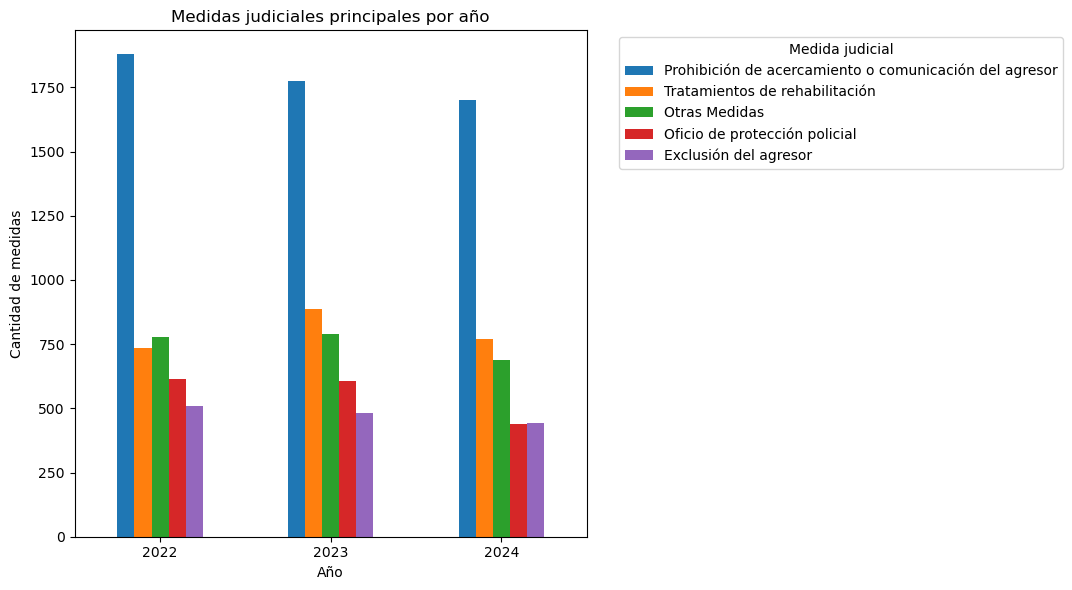

Gráfico guardado en: C:\Users\Luciano Sotelo\Documents\TESIS_PODER_JUDICIAL\04_graficos_resultados\17_medidas_judiciales_por_anio.png


,Prohibición de acercamiento o comunicación del agresor,Tratamientos de rehabilitación,Otras Medidas,Oficio de protección policial,Exclusión del agresor
Año,,,,,
2022,1878,733,777,614,510
2023,1775,888,788,608,483
2024,1702,771,690,438,443


In [22]:
medidas_principales = [
    "Prohibición de acercamiento o comunicación del agresor",
    "Tratamientos de rehabilitación",
    "Otras Medidas",
    "Oficio de protección policial",
    "Exclusión del agresor"
]

medidas_por_anio = df.groupby("Año")[medidas_principales].sum()

medidas_por_anio.plot(kind="bar", figsize=(11, 6))
plt.title("Medidas judiciales principales por año")
plt.xlabel("Año")
plt.ylabel("Cantidad de medidas")
plt.xticks(rotation=0)
plt.legend(title="Medida judicial", bbox_to_anchor=(1.05, 1), loc="upper left")

guardar_grafico("17_medidas_judiciales_por_anio.png")

medidas_por_anio

In [23]:
with pd.ExcelWriter(RUTA_RESUMEN) as writer:
    casos_por_anio.to_frame("Cantidad de casos").to_excel(writer, sheet_name="Casos por año")
    casos_mes_anio.to_excel(writer, sheet_name="Casos mes año", index=False)
    resumen_violencias.sort_values("Casos", ascending=False).to_excel(writer, sheet_name="Tipos violencia", index=False)
    tabla_gravedad_violencias.to_excel(writer, sheet_name="Gravedad violencia")
    resumen_medidas.to_excel(writer, sheet_name="Medidas judiciales", index=False)
    casos_departamento.sort_values(ascending=False).to_frame("Cantidad de casos").to_excel(writer, sheet_name="Departamentos")
    casos_localidad.sort_values(ascending=False).to_frame("Cantidad de casos").to_excel(writer, sheet_name="Localidades")
    frecuencia_episodios.to_frame("Cantidad de casos").to_excel(writer, sheet_name="Frecuencia episodios")
    relacion.sort_values(ascending=False).to_frame("Cantidad de casos").to_excel(writer, sheet_name="Relaciones")
    sexo_denunciante.to_frame("Cantidad de casos").to_excel(writer, sheet_name="Sexo denunciante")
    sexo_denunciada.to_frame("Cantidad de casos").to_excel(writer, sheet_name="Sexo denunciada")
    violencia_psicologica_anio.to_excel(writer, sheet_name="Psicologica por año")
    medidas_por_anio.to_excel(writer, sheet_name="Medidas por año")

print("Resumen guardado en:")
print(RUTA_RESUMEN)

Resumen guardado en:
C:\Users\Luciano Sotelo\Documents\TESIS_PODER_JUDICIAL\02_datos_limpios\resumen_resultados_v1.xlsx
